# 04 · Model: does the satellite beat the last lab result?

**User:** a COGERH water-quality technician (or the operator of a Jaguaribe Valley water service).
**Decision:** which reservoirs to sample first, and where to start toxin testing before the next quarterly lab campaign.
**Target:** `y = 1` when cyanobacteria exceed **20,000 cells/mL** (Portaria GM/MS 888/2021: weekly cyanotoxin testing).

Today the technician's best guess is the **last lab result** (persistence). The question is whether satellite + weather + stored volume, available any week, do better on **future campaigns the model never saw**.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import average_precision_score
from lightgbm import LGBMClassifier
import joblib

sys.path.insert(0, str(Path.cwd().parent / "src"))
from common import PROCESSED, OUTPUTS, CYANO_THRESHOLD
from modeling import FEATURES, SATELLITE, WEATHER, WATER, SEASON, time_split, metrics, threshold_for_recall, best_f1_threshold

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
df = pd.read_csv(PROCESSED / "features.csv", parse_dates=["date"])
df["prev_log10_cyano"] = np.log10(df["prev_cyano"].clip(lower=1))
print(df.shape, "| features:", FEATURES)

(614, 42) | features: ['NDCI', 'NDTI', 'MNDWI', 'water_frac', 'tmax_7d', 'tmax_30d', 'rain_30d', 'rain_90d', 'wind_7d', 'sw_7d', 'volume_pct', 'volume_change', 'month_sin', 'month_cos', 'rainy_season']


## Time split (no shuffling across time)

Campaigns in date order: the oldest ~60% train, the next ~20% validate (model and threshold choice), the newest ~20% test, used **once** at the end.

In [2]:
df["split"] = time_split(df)
summary = df.groupby("split").agg(campaigns=("campaign", "nunique"), first=("campaign", "min"), last=("campaign", "max"),
                                  first_date=("date", "min"), last_date=("date", "max"), samples=("y", "size"),
                                  positive_share=("y", "mean")).loc[["train", "val", "test"]]
summary

,campaigns,first,last,first_date,last_date,samples,positive_share
split,,,,,,,
train,16,2016-05,2020-02,2016-05-09,2020-02-12,288,0.743
val,5,2020-08,2021-08,2020-07-28,2021-09-14,142,0.915
test,6,2021-11,2025-02,2021-10-05,2025-03-12,184,0.870


In [3]:
tr, va, te = (df[df["split"] == s].copy() for s in ["train", "val", "test"])
print("samples without a previous lab result (first visit of a reservoir):",
      {s: int(d["prev_class"].isna().sum()) for s, d in [("train", tr), ("val", va), ("test", te)]})

samples without a previous lab result (first visit of a reservoir): {'train': 2, 'val': 1, 'test': 0}


## Baselines

1. **Persistence**: predict the class of the reservoir's previous lab campaign (what the technician knows today). Its score for PR-AUC is the previous count.
2. **Majority class**: always predict "bloom".
3. **NDCI rule**: bloom if NDCI > t, with t chosen on validation to maximise F1.

Every method is scored on the same rows: samples that have a previous lab result (otherwise persistence has nothing to say).

In [4]:
va_p, te_p = va[va["prev_class"].notna()].copy(), te[te["prev_class"].notna()].copy()
t_ndci = best_f1_threshold(va_p["y"], va_p["NDCI"].values)
print(f"NDCI threshold chosen on validation: {t_ndci:.4f}")

def baselines(d):
    return {
        "Persistence (last lab result)": metrics(d["y"], d["prev_class"].astype(int), d["prev_log10_cyano"]),
        "Majority class (always bloom)": metrics(d["y"], np.ones(len(d), int), np.ones(len(d))),
        "NDCI > t": metrics(d["y"], (d["NDCI"] > t_ndci).astype(int), d["NDCI"]),
    }
pd.DataFrame(baselines(va_p)).T

NDCI threshold chosen on validation: -0.0604


,n,positives,recall,precision,F1,balanced_acc,missed_blooms (FN),false_alarms (FP),TP,TN,PR_AUC
Persistence (last lab result),141.0,129.0,0.930,0.930,0.930,0.590,9.0,9.0,120.0,3.0,0.954
Majority class (always bloom),141.0,129.0,1.000,0.915,0.956,0.500,0.0,12.0,129.0,0.0,0.915
NDCI > t,141.0,129.0,0.977,0.947,0.962,0.697,3.0,7.0,126.0,5.0,0.962


## Models

1. **Logistic regression** on standardized features, balanced class weights. The primary model: its coefficients are the explanation.
2. **LightGBM**, kept small (depth 3, 200 trees, learning rate 0.05, balanced).
3. **Logistic regression + last lab result**: the same model with the previous count (log10) added, to see if satellites add to what the technician already knows.

Missing values (a few weather windows, volume change at a reservoir's first visit) are filled with the **training** median; the scaler is also fitted on training data only.

In [5]:
def logreg():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))

models = {
    "Logistic regression": (logreg(), FEATURES),
    "LightGBM (small)": (LGBMClassifier(max_depth=3, n_estimators=200, learning_rate=0.05, class_weight="balanced",
                                        random_state=SEED, verbose=-1), FEATURES),
    "Logistic regression + last lab": (logreg(), FEATURES + ["prev_log10_cyano"]),
}
val_scores = {}
for name, (m, cols) in models.items():
    m.fit(tr[cols], tr["y"])
    val_scores[name] = m.predict_proba(va_p[cols])[:, 1]
val_table = {"Persistence (last lab result)": va_p["prev_log10_cyano"], "NDCI alone": va_p["NDCI"], **val_scores}
pd.DataFrame({name: {"val PR_AUC": average_precision_score(va_p["y"], s)} for name, s in val_table.items()}).T

,val PR_AUC
Persistence (last lab result),0.954
NDCI alone,0.962
Logistic regression,0.951
LightGBM (small),0.928
Logistic regression + last lab,0.958


**Model choice (on validation only):** if logistic regression is within 0.02 PR-AUC of LightGBM, we keep logistic regression because it is easier to explain.

In [6]:
ap = {n: average_precision_score(va_p["y"], s) for n, s in val_scores.items()}
chosen = "Logistic regression" if ap["Logistic regression"] >= ap["LightGBM (small)"] - 0.02 else "LightGBM (small)"
print("chosen satellite model:", chosen, {k: round(v, 3) for k, v in ap.items()})

chosen satellite model: Logistic regression {'Logistic regression': 0.951, 'LightGBM (small)': 0.928, 'Logistic regression + last lab': 0.958}


## Decision threshold (validation)

Missing a bloom is worse than an extra sample, so the threshold is the highest one that still catches **at least 80% of blooms** on validation.

In [7]:
thresholds = {n: threshold_for_recall(va_p["y"], s, 0.80) for n, s in val_scores.items()}
print({k: round(v, 3) for k, v in thresholds.items()})

{'Logistic regression': 0.256, 'LightGBM (small)': 0.373, 'Logistic regression + last lab': 0.334}


## Test: future campaigns, used once

In [8]:
test_scores = {n: m.predict_proba(te_p[cols])[:, 1] for n, (m, cols) in models.items()}
rows = baselines(te_p)
for n, s in test_scores.items():
    rows[n] = metrics(te_p["y"], (s >= thresholds[n]).astype(int), s)
results = pd.DataFrame(rows).T
results[["n", "positives", "recall", "precision", "F1", "PR_AUC", "balanced_acc", "missed_blooms (FN)", "false_alarms (FP)", "TP", "TN"]]

,n,positives,recall,precision,F1,PR_AUC,balanced_acc,missed_blooms (FN),false_alarms (FP),TP,TN
Persistence (last lab result),184.0,160.0,0.900,0.889,0.894,0.931,0.575,16.0,18.0,144.0,6.0
Majority class (always bloom),184.0,160.0,1.000,0.870,0.930,0.870,0.500,0.0,24.0,160.0,0.0
NDCI > t,184.0,160.0,0.994,0.893,0.941,0.962,0.601,1.0,19.0,159.0,5.0
Logistic regression,184.0,160.0,0.894,0.888,0.891,0.944,0.572,17.0,18.0,143.0,6.0
LightGBM (small),184.0,160.0,0.881,0.928,0.904,0.943,0.711,19.0,11.0,141.0,13.0
Logistic regression + last lab,184.0,160.0,0.875,0.886,0.881,0.952,0.562,20.0,18.0,140.0,6.0


### Leakage check

Some PR-AUC values are above 0.95, which our own rule says to treat as a warning sign. Three checks:

1. **Chance level.** PR-AUC of a random guess equals the share of blooms in the test set, which is very high here.
2. **No lab values among the inputs**, and a model trained on **shuffled labels** must fall back to chance.
3. **The hard direction.** Because blooms are the norm, we also score how well each method finds the *clean* reservoirs (PR-AUC for y = 0).

In [9]:
print(f"chance level (share of blooms in test): {te_p['y'].mean():.3f}")
lab_columns = {"cyano", "chla", "y", "prev_cyano", "prev_class", "prev_log10_cyano", "n_total", "p_total", "transparency"}
assert not set(FEATURES) & lab_columns, "a lab value is among the satellite-model inputs"
rng_l = np.random.default_rng(SEED)
shuffled = [average_precision_score(te_p["y"], logreg().fit(tr[FEATURES], rng_l.permutation(tr["y"].values))
                                    .predict_proba(te_p[FEATURES])[:, 1]) for _ in range(20)]
print(f"logistic regression trained on shuffled labels: test PR-AUC {np.mean(shuffled):.3f} (mean of 20 shuffles)")

scores = {"Persistence (last lab result)": te_p["prev_log10_cyano"].values, "Majority class (always bloom)": np.ones(len(te_p)),
          "NDCI > t": te_p["NDCI"].values, **test_scores}
results["PR_AUC_clean"] = pd.Series({n: average_precision_score(1 - te_p["y"], -s) for n, s in scores.items()})
print()
print(f"finding the clean reservoirs (PR-AUC for y = 0; chance = {1 - te_p['y'].mean():.3f}):")
print(results["PR_AUC_clean"].round(3).to_string())
results.to_csv(OUTPUTS / "test_results.csv")

chance level (share of blooms in test): 0.870


logistic regression trained on shuffled labels: test PR-AUC 0.868 (mean of 20 shuffles)

finding the clean reservoirs (PR-AUC for y = 0; chance = 0.130):
Persistence (last lab result)     0.281
Majority class (always bloom)     0.130
NDCI > t                          0.455
Logistic regression               0.225
LightGBM (small)                  0.425
Logistic regression + last lab    0.268


### How sure are these differences? (bootstrap)

We resample the test samples 1,000 times and recompute PR-AUC, to see whether the gap between the model and persistence is bigger than chance.

In [10]:
rng = np.random.default_rng(SEED)
y = te_p["y"].values
pers = te_p["prev_log10_cyano"].values
idx = [i for i in (rng.integers(0, len(y), len(y)) for _ in range(1000)) if y[i].min() != y[i].max()]
for label, mod in [(chosen, test_scores[chosen]), ("NDCI alone", te_p["NDCI"].values)]:
    diffs = [average_precision_score(y[i], mod[i]) - average_precision_score(y[i], pers[i]) for i in idx]
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    print(f"PR-AUC({label}) - PR-AUC(persistence): mean {np.mean(diffs):+.3f}, 95% interval [{lo:+.3f}, {hi:+.3f}]")

PR-AUC(Logistic regression) - PR-AUC(persistence): mean +0.013, 95% interval [-0.030, +0.056]


PR-AUC(NDCI alone) - PR-AUC(persistence): mean +0.030, 95% interval [-0.005, +0.071]


### Why not just use NDCI?

On these test campaigns the single-index rule "NDCI > t" has the highest PR-AUC (0.962), missed only 1 bloom, and raised 19 false alarms; the logistic regression missed 17 with 18 false alarms. Its interval against persistence (−0.005 to +0.071) also includes zero, so it ties the last lab result too. The chlorophyll seen from space is the core signal. What the model adds is a calibrated probability, a ranking, stored volume and plain-language reasons, not a better score here.

Balanced accuracy (a secondary metric, in the table above) points the same way: NDCI 0.601, logistic regression 0.572, persistence 0.575; the small LightGBM is highest (0.711).

## Explainability

Logistic regression (model A, the model chosen here; the map later uses model B, see notebook 04b): each bar is how much one standard deviation of that feature changes the log-odds of a bloom.

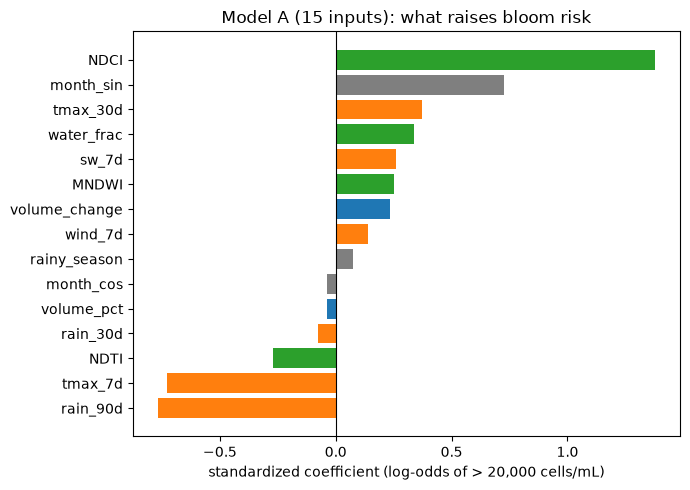

,rain_90d,tmax_7d,NDTI,rain_30d,volume_pct,month_cos,rainy_season,wind_7d,volume_change,MNDWI,sw_7d,water_frac,tmax_30d,month_sin,NDCI
coefficient,-0.769,-0.728,-0.272,-0.076,-0.039,-0.039,0.075,0.14,0.235,0.253,0.259,0.338,0.371,0.726,1.378


In [11]:
lr = models["Logistic regression"][0]
coef = pd.Series(lr[-1].coef_[0], index=FEATURES).sort_values()
group = {**{f: "satellite" for f in SATELLITE}, **{f: "weather" for f in WEATHER}, **{f: "water stored" for f in WATER}, **{f: "season" for f in SEASON}}
palette = {"satellite": "tab:green", "weather": "tab:orange", "water stored": "tab:blue", "season": "tab:gray"}
colors = [palette[group[f]] for f in coef.index]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(coef.index, coef.values, color=colors)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("standardized coefficient (log-odds of > 20,000 cells/mL)")
ax.set_title("Model A (15 inputs): what raises bloom risk")
plt.tight_layout(); plt.savefig(OUTPUTS / "lr_coefficients_modelA.png", dpi=120); plt.show()
coef.round(3).to_frame("coefficient").T

**Reading the chart with care.** Some inputs measure almost the same thing. When two inputs move together, the model can split one effect between them with opposite signs, so their bars must be read together, not one by one. Below: how strongly the related inputs move together in the training data, and how each relates to blooms on its own. The risk map adds such groups together (heat = both temperature windows, rain = both rain windows, season = month + rainy-season flag) before choosing the top 3 reasons.

In [12]:
from scipy.stats import spearmanr
print("correlation in training data:",
      {f"{a} vs {b}": round(tr[a].corr(tr[b]), 2) for a, b in [("tmax_7d", "tmax_30d"), ("rain_30d", "rain_90d"), ("tmax_7d", "month_sin")]})
print("each input alone vs bloom (Spearman, training):",
      {f: round(spearmanr(tr[f], tr["y"], nan_policy="omit")[0], 2) for f in ["NDCI", "tmax_7d", "tmax_30d", "rain_30d", "rain_90d", "month_sin"]})

correlation in training data: {'tmax_7d vs tmax_30d': np.float64(0.91), 'rain_30d vs rain_90d': np.float64(0.76), 'tmax_7d vs month_sin': np.float64(-0.7)}
each input alone vs bloom (Spearman, training): {'NDCI': np.float64(0.41), 'tmax_7d': np.float64(-0.04), 'tmax_30d': np.float64(0.02), 'rain_30d': np.float64(0.05), 'rain_90d': np.float64(-0.01), 'month_sin': np.float64(0.1)}


**SHAP summary: LightGBM, for comparison only (not used in the map).** The map uses a logistic regression (model B, notebook 04b), whose coefficients are the explanation.

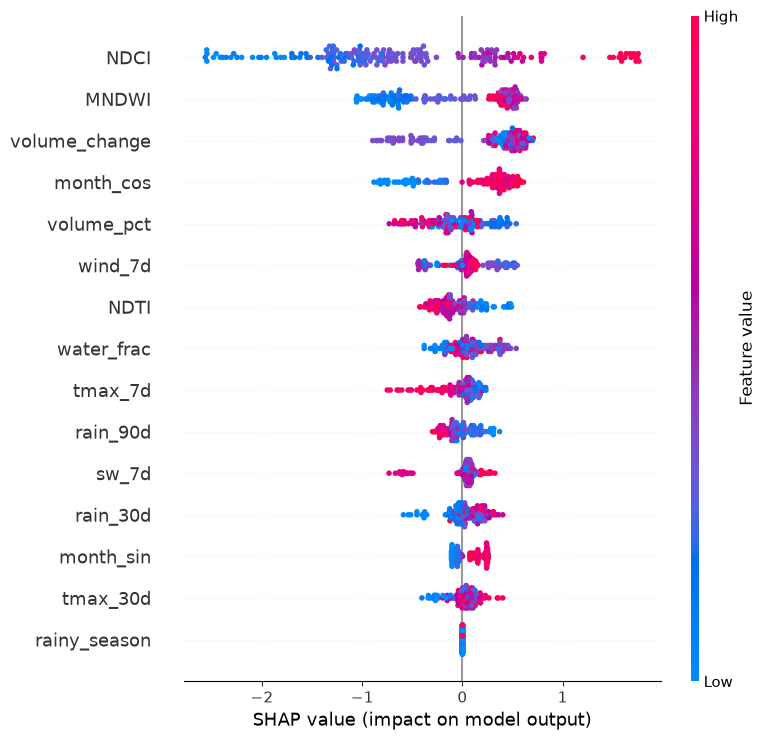

In [13]:
import shap
lgbm = models["LightGBM (small)"][0]
explainer = shap.TreeExplainer(lgbm)
sv = explainer(te_p[FEATURES])
shap.summary_plot(sv, te_p[FEATURES], show=False)
plt.tight_layout(); plt.savefig(OUTPUTS / "lgbm_shap_summary.png", dpi=110); plt.show()

## Our own questions

1. **Drought:** does the model work as well when the reservoir is below 20% of its volume?
2. **Unseen reservoirs:** train on some reservoirs and test on others (5 folds grouped by reservoir).
3. **Date gap:** do results change if we keep only samples where the image is within 2 days of the lab visit?

In [14]:
s_test = test_scores[chosen]
pred = (s_test >= thresholds[chosen]).astype(int)
low = te_p["volume_pct"] < 20
q1 = pd.DataFrame({
    "volume < 20%": metrics(te_p["y"][low], pred[low.values], s_test[low.values]),
    "volume >= 20%": metrics(te_p["y"][~low], pred[~low.values], s_test[~low.values]),
}).T[["n", "positives", "recall", "precision", "missed_blooms (FN)", "false_alarms (FP)"]]
q1

,n,positives,recall,precision,missed_blooms (FN),false_alarms (FP)
volume < 20%,38.0,35.0,0.886,0.912,4.0,3.0
volume >= 20%,146.0,125.0,0.896,0.882,13.0,15.0


In [15]:
gkf = GroupKFold(n_splits=5)
rows = []
for k, (i_tr, i_te) in enumerate(gkf.split(df, df["y"], groups=df["reservoir"])):
    a, b = df.iloc[i_tr], df.iloc[i_te]
    m = logreg().fit(a[FEATURES], a["y"])
    bp = b[b["prev_class"].notna()]
    rows.append({"fold": k, "test_reservoirs": b["reservoir"].nunique(), "n": len(bp),
                 "PR_AUC model": average_precision_score(bp["y"], m.predict_proba(bp[FEATURES])[:, 1]),
                 "PR_AUC persistence": average_precision_score(bp["y"], bp["prev_log10_cyano"])})
q2 = pd.DataFrame(rows)
print(q2.round(3).to_string(index=False))
print("mean:", q2[["PR_AUC model", "PR_AUC persistence"]].mean().round(3).to_dict())

 fold  test_reservoirs   n  PR_AUC model  PR_AUC persistence
    0               12 122         0.876               0.890
    1               12 122         0.981               0.988
    2               12 123         0.808               0.819
    3               13 122         0.937               0.893
    4               12 122         0.963               0.976
mean: {'PR_AUC model': 0.913, 'PR_AUC persistence': 0.913}


In [16]:
near = (te_p["day_gap"] <= 2).values
q3 = pd.DataFrame({
    "all test samples": metrics(te_p["y"], pred, s_test),
    "image within 2 days": metrics(te_p["y"][near], pred[near], s_test[near]),
}).T[["n", "recall", "precision", "PR_AUC"]]
q3

,n,recall,precision,PR_AUC
all test samples,184.0,0.894,0.888,0.944
image within 2 days,130.0,0.883,0.860,0.937


## Where it fails

The 5 worst missed blooms (lowest predicted risk among real blooms) and the 5 worst false alarms (highest risk among clean samples) in the test campaigns.

In [17]:
te_p["risk"] = s_test
cols_show = ["reservoir", "date", "img_date", "day_gap", "cyano", "chla", "risk", "NDCI", "NDTI", "water_frac", "volume_pct", "n_water_px"]
fn = te_p[(te_p["y"] == 1)].nsmallest(5, "risk")[cols_show]
fp = te_p[(te_p["y"] == 0)].nlargest(5, "risk")[cols_show]
print("Missed blooms:"); display(fn)
print("False alarms:"); display(fp)

Missed blooms:


,reservoir,date,img_date,day_gap,cyano,chla,risk,NDCI,NDTI,water_frac,volume_pct,n_water_px
434,rosario,2021-10-19,2021-10-20,1.0,38509.0,NaN,0.134,-0.020,-0.147,0.198,78.3,221.0
443,riacho do sangue,2021-11-24,2021-11-24,0.0,191134.0,12.85,0.136,0.006,-0.082,0.267,62.4,373.0
435,canafistula,2021-11-04,2021-11-09,5.0,502613.0,25.08,0.147,0.015,-0.051,0.137,20.1,135.0
439,ema,2021-11-11,2021-11-09,2.0,357493.0,32.23,0.152,0.003,-0.056,0.323,30.2,232.0
444,bengue,2021-12-15,2021-12-19,4.0,136272.0,9.68,0.165,-0.031,-0.136,0.162,29.5,192.0


False alarms:


,reservoir,date,img_date,day_gap,cyano,chla,risk,NDCI,NDTI,water_frac,volume_pct,n_water_px
592,cachoeira,2025-01-14,2025-01-17,3.0,1062.0,NaN,0.819,0.056,-0.143,0.259,85.3,240.0
613,bengue,2025-03-12,2025-03-13,1.0,10422.0,NaN,0.665,0.014,-0.108,0.243,95.6,380.0
462,atalho,2022-02-02,2022-02-02,0.0,16046.0,6.01,0.588,0.024,-0.209,0.312,31.9,353.0
476,olho d agua,2022-10-05,2022-10-05,0.0,1415.0,NaN,0.555,0.016,-0.020,0.418,88.4,666.0
536,poco da pedra,2024-07-02,2024-07-01,1.0,4130.0,13.90,0.530,0.008,-0.164,0.433,9.1,188.0


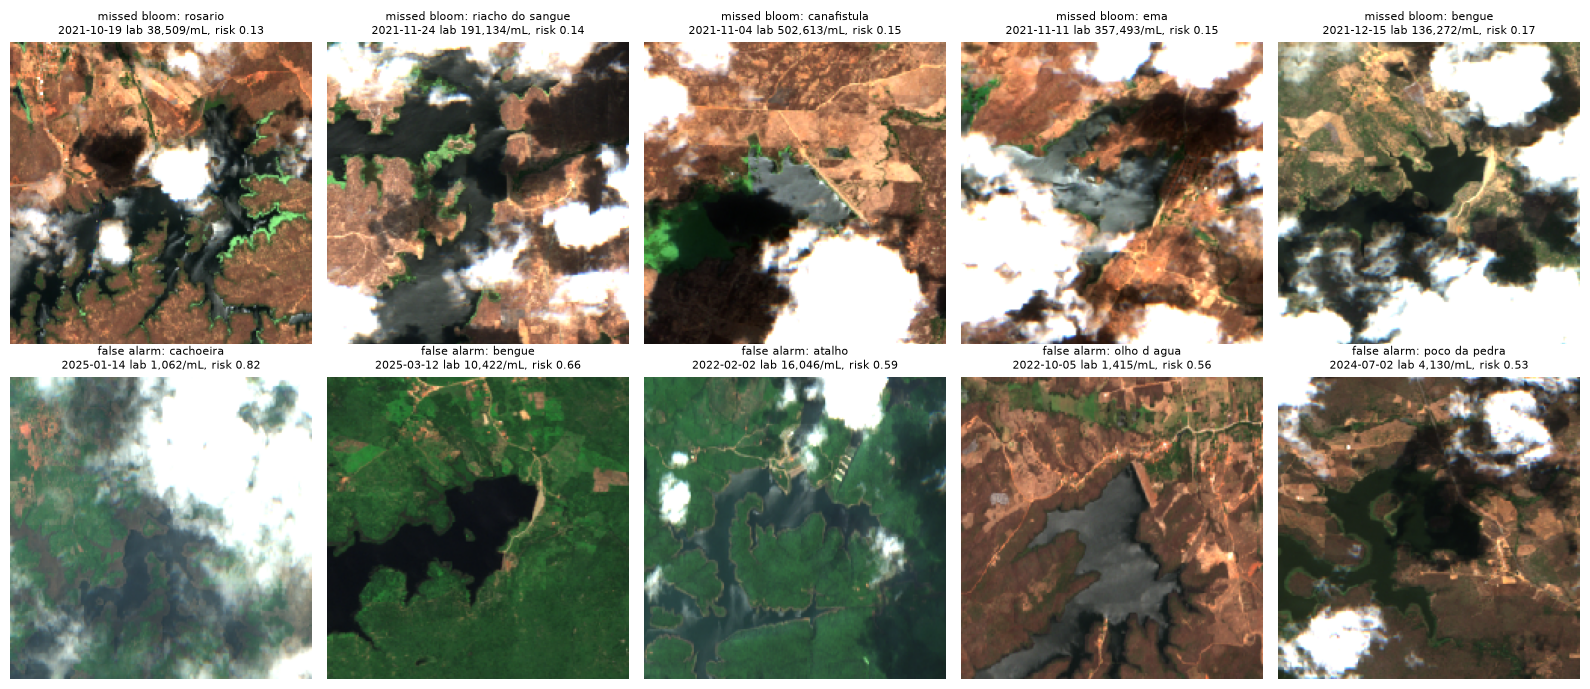

In [18]:
import geopandas as gpd
from satellite import rgb_thumbnail
aois = gpd.read_file(PROCESSED / "reservoirs.geojson").set_index("reservoir").geometry
cases = pd.concat([fn.assign(kind="missed bloom"), fp.assign(kind="false alarm")])
cases = cases.join(te_p["item_id"])
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, (_, r) in zip(axes.flat, cases.iterrows()):
    try:
        ax.imshow(rgb_thumbnail(r["item_id"], aois[r["reservoir"]].bounds))
    except Exception as e:
        ax.text(0.5, 0.5, "thumbnail failed", ha="center")
    ax.set_title(f"{r['kind']}: {r['reservoir']}\n{r['date'].date()} lab {r['cyano']:,.0f}/mL, risk {r['risk']:.2f}", fontsize=8)
    ax.axis("off")
for ax in list(axes.flat)[len(cases):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(OUTPUTS / "failures_rgb.png", dpi=110); plt.show()

### Checking the failure hypotheses on the whole test set

Ten thumbnails can mislead, so each hypothesis is checked on all test samples:

- **Clouds:** are errors more common when part of the area near the sampling point is cloudy (clear share < 90%)?
- **Season:** are errors more common in the dry-season campaigns (Aug, Nov)? And did the share of blooms in each season change between the training years and the test years?

In [19]:
te_p["wrong"] = pred != te_p["y"].values
te_p["missed"] = te_p["wrong"] & (te_p["y"] == 1)
te_p["clear_share"] = te_p["n_clear_px"] / te_p["n_aoi_px"]
te_p["scene"] = np.where(te_p["clear_share"] < 0.9, "partly cloudy", "clear")
df["season"] = np.where(df["campaign"].str[-2:].isin(["08", "11"]), "dry (Aug, Nov)", "wet (Feb, May)")
te_p["season"] = df.loc[te_p.index, "season"]
for col in ["scene", "season"]:
    print(te_p.groupby(col).agg(n=("y", "size"), error_rate=("wrong", "mean"), missed_blooms=("missed", "sum"),
                                mean_risk=("risk", "mean")).round(2).to_string())
    print()
print("share of samples above 20,000 cells/mL, by season:")
print(pd.crosstab(df["split"], df["season"], values=df["y"], aggfunc="mean").loc[["train", "val", "test"]].round(2).to_string())
print()
print("errors by test campaign:")
print(te_p.groupby("campaign").agg(n=("y", "size"), blooms=("y", "sum"), missed=("missed", "sum"), false_alarms=("wrong", "sum"))
      .assign(false_alarms=lambda d: d["false_alarms"] - d["missed"]).to_string())

                n  error_rate  missed_blooms  mean_risk
scene                                                  
clear          86        0.24             11       0.48
partly cloudy  98        0.14              6       0.58

                 n  error_rate  missed_blooms  mean_risk
season                                                  
dry (Aug, Nov)  99        0.28             16       0.45
wet (Feb, May)  85        0.08              1       0.64

share of samples above 20,000 cells/mL, by season:
season  dry (Aug, Nov)  wet (Feb, May)
split                                 
train             0.70            0.79
val               0.95            0.86
test              0.84            0.91

errors by test campaign:
           n  blooms  missed  false_alarms
campaign                                  
2021-11   16      16       8             0
2022-02   26      22       1             3
2022-11   29      23       4             5
2024-02   33      32       0             1
2024-08   54    

### Why it fails (hypotheses, checked where we could)

**Missed blooms.** The five worst are all from the Oct–Dec 2021 campaign.
- *Season, not clouds.* All five thumbnails show broken clouds and shadows, so clouds were our first guess. The whole test set does not support it: partly cloudy scenes had **fewer** errors than clear ones. What the errors do share is the season: almost all missed blooms are in the dry-season campaigns (Aug, Nov). In the training years, dry-season samples were blooms less often than wet-season ones, so the model learned "dry season, slightly lower risk" through the season and temperature inputs. In the test years, dry-season blooms became as common as wet-season ones, and the learned pattern no longer held. The satellite colour signal was weak in these five as well (NDCI from −0.031 to 0.015).
- *Many cells, little chlorophyll.* Riacho do Sangue had 191,134 cells/mL with only 12.85 µg/L of chlorophyll-a, and Bengue 136,272 cells/mL with 9.68 µg/L. NDCI follows chlorophyll (Spearman 0.81 in notebook 03) much more than cell counts (0.41), so a bloom of many small cells can look "not green" from space.

**False alarms.**
- *Close to the line.* Atalho (16,046 cells/mL) and Bengue in 2025 (10,422) were below 20,000 but not far below it.
- *Green, but not cyanobacteria.* Poço da Pedra had 13.90 µg/L of chlorophyll-a but only 4,130 cyanobacteria cells/mL: the water was green from other algae, and NDCI cannot tell algae groups apart. It was also at 9.1% of its volume.
- *Haze.* Cachoeira (risk 0.82, only 1,062 cells/mL) is covered by haze and thin cloud in its thumbnail and has the highest NDCI of the five. In Olho d'Água the water looks bright grey, which suggests haze or sun glint.

**What we take from this.** The chlorophyll colour (NDCI) is the part that held up on future years. The calendar and temperature inputs learned a pattern that changed. Next time we would test a model without them, and we would not re-tune on these test campaigns.

## Save the chosen model for the risk map

In [20]:
final_name = chosen
final_model = models[final_name][0]
joblib.dump({"name": final_name, "model": final_model, "features": FEATURES, "threshold": thresholds[final_name],
             "train_campaigns": sorted(tr["campaign"].unique())}, OUTPUTS / "model.joblib")
print("saved", final_name, "threshold", round(thresholds[final_name], 3))

saved Logistic regression threshold 0.256
